# C0 · HTO · High tier (UNet-64) · round-blob baseline B0: 5 folds × seed 101 (axis-definition runs)

**Why.** The HTO pre-screen (`C0_HTO_prescreen.ipynb`) showed that HTO's labels are 3–4× more precise relative to the blob than
ISBI's, so HTO could sit in the strong-transfer regime. The deciding unknown is m = network error SD ÷ ground-truth-noise SD. These
runs measure it with an ordinary round blob (B0), before any oval run and before the forecast is deposited. They show the
baseline error only, nothing about ovals.

**Role in the HTO design.** Seed 101 marks these as the **axis-definition** runs of the plan's HTO arm (plan §4.2: "5 folds × 2 seeds
plus 5 axis-definition runs"): later they fix the oval directions, and they are never used as paired baselines (the paired B0 runs,
seeds 1–2, train together with the oval arms). So nothing here is wasted.

**Protocol.** Everything is the ISBI High arm R protocol (code copied verbatim by `build_hto_b0.py`), with an explicit HTO update of
`PROTOCOL` in §0: data, 12 landmarks (6 per leg), 5-fold patient-level CV, ground truth = mean of the three specialists, canvas
1024 × 480 (aspect of a long-leg film; same pixel count as ISBI's 768 × 640), σ₀ = 5 canvas px (as ISBI High), an iteration
budget matched to ISBI High (≈ 29,600 iterations), and pixel units: HTO films store no pixel spacing, so **every `*_mm` quantity in
this notebook is in original image pixels** (`pixel_mm = 1` by convention). Gross failure = 100 original px (PROVISIONAL; about the
95th percentile of the specialists' pairwise disagreement at the hinge point, the noisiest landmark).

**Runs.** 5 runs, one per fold (`C0_HTO_High_R_w1.00_f<fold>_s101`). Five GPU copies (`_gpu0_1`, `_gpu1_1`, `_gpu0_2`, `_gpu1_2`,
`_gpu0_3`), one fold each, started together: one wave, roughly 2.5–3 h (an estimate; the first epoch prints the projection).
The pod needs the HTO data at `DATA_ROOT` (`data/hto/xrays` of the repo: the PNGs and `specialists_labels.json`).

**Progress.** One progress bar per run, advanced every epoch (loss, MRE on 20 training films in original px, s/epoch, ETA);
without tqdm a line is printed every 25 epochs. `PROGRESS_BAR` is not part of `PROTOCOL`.

**Analysis.** §10 prints a status table. The forecast analysis (m per landmark, ρ, point forecast) runs locally in
`C0_HTO_prescreen.ipynb` §5, which reads these runs. Exploratory; part of the HTO pre-screen before the deposit.

> **GPU 1, notebook 1 on this GPU: fold 2 only.** Identical to `C0_HTO_High_B0.ipynb` except for `RUN_IDS` and `GPU` in the parameters cell, neither of which is part of `PROTOCOL`. Start all five at the same time on a 2-GPU pod, each in its own kernel, with the same `RUN_ROOT`. If you change `GPU`, restart the kernel first.

In [1]:
import os

DATASET = "HTO"
TIER = "High"
ARM = "R"

RUN_IDS = ["C0_HTO_High_R_w1.00_f2_s101"]   # this notebook: fold 2
SMOKE_TEST = False      # True: real HTO data on a tiny canvas, tiny UNet, 4 epochs; checks the pipeline only

DATA_ROOT = os.environ.get("HTO_ROOT", "/tf/data/hto/xrays")
# Runs go to the persistent RunPod volume (/workspace) when it exists; the container disk is wiped when the pod stops.
# All notebooks that share runs (e.g. the part 1-3 copies) must use the same RUN_ROOT.
RUN_ROOT = os.environ.get("C0_RUN_ROOT", "/workspace/C0/HTO_High" if os.path.isdir("/workspace")
                          else "/tf/weights/C0/HTO_High")

SIGMA0_PX = 5.0         # σ₀ in canvas pixels, as ISBI High (≈ 37 original px at the median film height)
EPOCHS = 2960          # iteration budget matched to ISBI High (see PROTOCOL["iteration_budget"])
BATCH_SIZE = 4
NUM_WORKERS = 6
GPU = 1                 # physical GPU used by this notebook
PROGRESS_BAR = True     # one progress bar per run, advanced every epoch (loss, training-subset MRE, s/epoch, ETA)

## 0. Setup and frozen protocol

In [2]:
import sys
if GPU is not None:
    # must happen before PyTorch initialises CUDA in this kernel
    if "torch" in sys.modules and sys.modules["torch"].cuda.is_initialized():
        raise RuntimeError("GPU can only be chosen before PyTorch starts: restart the kernel and run from the top.")
    os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU)
import json, math, re, time, hashlib, platform, subprocess, warnings, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

cv2.setNumThreads(0)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    # Fail fast if this PyTorch build has no kernels for the GPU (e.g. Blackwell sm_120 with a cu121/cu124 wheel)
    _maj, _min = torch.cuda.get_device_capability(0)
    _arch, _built = f"sm_{_maj}{_min}", torch.cuda.get_arch_list()
    if _arch not in _built:
        raise RuntimeError(f"{torch.cuda.get_device_name(0)} is {_arch}, but this PyTorch {torch.__version__} "
                           f"(CUDA {torch.version.cuda}) only has kernels for {_built}. For Blackwell (sm_120) install "
                           "PyTorch >= 2.7 built for CUDA >= 12.8, e.g. pip install --upgrade torch torchvision "
                           "--index-url https://download.pytorch.org/whl/cu128, then restart the kernel.")
    _ = (torch.ones(256, 256, device=DEVICE) @ torch.ones(256, 256, device=DEVICE)).sum().item()
if GPU is not None and DEVICE.type == "cuda":
    assert torch.cuda.device_count() == 1, f"expected only GPU {GPU} to be visible, got {torch.cuda.device_count()}"
if os.name == "nt" or SMOKE_TEST:
    NUM_WORKERS = 0          # notebook-defined Dataset classes cannot be pickled to spawned workers

LANDMARKS_LEG = ["femur_head", "knee_inner", "ost_point", "knee_outer", "ankle_inner", "ankle_outer"]
LANDMARKS = [f"{side} {n}" for side in ("left", "right") for n in LANDMARKS_LEG]     # slot order of the HTO paper
K = len(LANDMARKS)

# 5-fold patient-level CV (one radiograph per patient), frozen in PROTOCOL
N_FOLDS = 5
_SPEC = json.loads((Path(DATA_ROOT) / "specialists_labels.json").read_text(encoding="utf-8"))
_NAMES = sorted(next(iter(_SPEC.values())).keys(), key=lambda n: int(n.split("_")[0]))
_perm = np.random.default_rng(20261011).permutation(len(_NAMES))
FOLDS = {_NAMES[j]: int(r % N_FOLDS) + 1 for r, j in enumerate(_perm)}

PROTOCOL = {
    # data
    "dataset": "ISBI 2015 cephalometric challenge (Wang et al., MedIA 2016)",
    "n_landmarks": K, "pixel_mm": 0.1,
    "split": {"train": [1, 150], "test1": [151, 300], "test2": [301, 400]},
    "ground_truth": "mean of senior and junior annotations",                         # PROVISIONAL
    "canvas_hw": [768, 640],
    "resize": "uniform scale s = min(768/H, 640/W); Gaussian pre-blur sigma 0.4/s; warpAffine bilinear, "
              "pixel-centre map x_c = s*(u+0.5)-0.5; zero pad right/bottom",
    "intensity": "[0,1] then per-sample z-score over the canvas",
    # network
    "tier": "High", "backbone": "UNet, base width 64, 4 levels, 3x3 conv + BN + ReLU, 2x2 transposed conv, "
                                "1x1 head, heatmaps at input resolution, no output activation",
    # target and loss
    "target": "unnormalised Gaussian exp(-0.5 d^T S^-1 d), peak 1, S in canvas px^2; the rotation part of the "
              "augmentation is applied to S (R S R^T), the scale part is not",
    "loss": "per-channel sum of squared error divided by that channel's analytic target mass 2*pi*sqrt(det S); "
            "landmarks outside the canvas after augmentation are excluded; mean over the remaining channels and batch",
    # optimisation
    "optimiser": {"name": "AdamW", "lr": 1e-3, "weight_decay": 1e-4, "warmup_epochs": 5,
                  "schedule": "cosine to 1e-6 per iteration"},                       # PROVISIONAL
    "epochs": EPOCHS, "batch_size": BATCH_SIZE, "drop_last": True,
    "amp": "bf16 autocast if supported, else fp16 with GradScaler",
    "augmentation": {"rot_deg": 10.0, "scale": [0.9, 1.1], "shift_frac": 0.05, "contrast": 0.2,
                     "brightness": 0.2, "gamma": [0.8, 1.25], "hflip": False},       # PROVISIONAL
    "seed_streams": "seed -> model init (torch); per-epoch order and per-sample augmentation from "
                    "numpy default_rng([seed, epoch, index]) so arms with equal seed see identical data",
    "checkpoint_used": "final epoch, no selection; fp16 snapshots at 50% and 75% for a post-hoc convergence report",
    "checkpoint_naming": "<stem>_<last 8 hex of the file's SHA-256>.pt (stem = final, snap_e50pct, snap_e75pct); "
                         "full SHA-256 in config.json; suffix re-verified on every load",
    "convergence_check": "MRE on 20 fixed training images (no augmentation) every 25 epochs; converged if the "
                         "mean of the last 4 checks is within 2% of the mean of the 4 before",
    # decoding and evaluation
    "decoders": ["argmax", "quadratic", "softargmax_local", "gaussfit"],
    "primary_decoder": "quadratic",                                                  # PROVISIONAL (fixed in WP0)
    "decoder_window_radius_px": 15,                                                  # PROVISIONAL, same in every arm
    "gross_failure_mm": 4.0, "sdr_mm": [2.0, 2.5, 3.0, 4.0],
    "error_frame": "original image, x right, y down, mm; angles from +x towards +y",
}


# ---- HTO update of the ISBI High protocol (everything not listed here is identical to ISBI High arm R) ----
for _k in ("split", "ground_truth"):
    PROTOCOL.pop(_k)
PROTOCOL.update({
    "dataset": "HTO long-leg radiographs (Mendeley/Ortotop): 54 radiographs, both legs, 6 landmarks per leg",
    "landmarks": LANDMARKS,
    "pixel_mm": 1.0,
    "units": "HTO films store no pixel spacing: every *_mm quantity is in ORIGINAL IMAGE PIXELS (pixel_mm = 1 by convention)",
    "cv": {"scheme": "5-fold patient-level CV, one radiograph per patient, folds from default_rng(20261011)", "folds": FOLDS},
    "ground_truth_hto": "mean of the three specialists (specialists_labels.json)",
    "canvas_hw": [1024, 480],
    "resize": "uniform scale s = min(1024/H, 480/W); Gaussian pre-blur sigma 0.4/s; warpAffine bilinear, "
              "pixel-centre map x_c = s*(u+0.5)-0.5; zero pad right/bottom",
    "epochs": EPOCHS,
    "iteration_budget": "matched to ISBI High (800 epochs x 37 = 29,600): 2,960 epochs x 10-11 iterations (43-44 training images)",
    "optimiser": {"name": "AdamW", "lr": 1e-3, "weight_decay": 1e-4, "warmup_epochs": 18,
                  "schedule": "cosine to 1e-6 per iteration"},
    "convergence_check": "MRE on 20 fixed training images of the run's fold (no augmentation) every 25 epochs; converged if "
                         "the mean of the last 4 checks is within 2% of the mean of the 4 before",
    "gross_failure_mm": 100.0,                                                       # PROVISIONAL, original px
    "sdr_mm": [25.0, 50.0, 75.0, 100.0],                                             # original px
    "error_frame": "original image, x right, y down, original px; angles from +x towards +y",
})

if SMOKE_TEST:
    RUN_ROOT = str(Path("c0_hto_smoke_runs").resolve())
    EPOCHS, SIGMA0_PX = 4, 1.5   # 4 so the 50% and 75% snapshots are distinct epochs
    PROTOCOL.update({"canvas_hw": [96, 48], "epochs": EPOCHS, "gross_failure_mm": 1e9,
                     "decoder_window_radius_px": 4, "smoke_test": True})
UNET_BASE = 8 if SMOKE_TEST else 64

PROTOCOL_HASH = hashlib.sha256(json.dumps(PROTOCOL, sort_keys=True).encode()).hexdigest()[:16]
H_C, W_C = PROTOCOL["canvas_hw"]
MM = PROTOCOL["pixel_mm"]
R_WIN = PROTOCOL["decoder_window_radius_px"]
Path(RUN_ROOT).mkdir(parents=True, exist_ok=True)

def _git_commit():
    for d in ("/tf", "."):
        try:
            return subprocess.check_output(["git", "-C", d, "rev-parse", "HEAD"], stderr=subprocess.DEVNULL,
                                           text=True).strip()
        except Exception:
            pass
    return None

ENV_INFO = {
    "python": platform.python_version(), "torch": torch.__version__, "cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "gpu_arch": _arch if DEVICE.type == "cuda" else None,
    "torch_arch_list": torch.cuda.get_arch_list() if DEVICE.type == "cuda" else None,
    "opencv": cv2.__version__, "numpy": np.__version__, "git_commit": _git_commit(),
    "host": platform.node(), "cuda_visible_devices": os.environ.get("CUDA_VISIBLE_DEVICES"),
}
AMP_DTYPE = (torch.bfloat16 if (DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()) else
             torch.float16 if DEVICE.type == "cuda" else None)
torch.backends.cudnn.benchmark = DEVICE.type == "cuda"
print("protocol", PROTOCOL_HASH, "| device", ENV_INFO["gpu"], "| amp", AMP_DTYPE, "| smoke", SMOKE_TEST)

protocol b95c046a70a62341 | device NVIDIA RTX PRO 6000 Blackwell Server Edition | amp torch.bfloat16 | smoke False


## 1. Run table: B0 axis-definition runs, one per fold

`width_mult` is w; the target SD in canvas pixels is w · σ₀. Only w = 1 (B0) here.

In [3]:
WIDTHS = {"0.50": 0.5, "0.71": 2 ** -0.5, "1.00": 1.0, "1.41": 2 ** 0.5, "2.00": 2.0}   # arm R grid: used only by the §3 target checks
AXIS_SEED = 101

def _run_row(fold):
    return {"run_id": f"C0_HTO_{TIER}_{ARM}_w1.00_f{fold}_s{AXIS_SEED}", "dataset": DATASET, "tier": TIER, "arm": ARM,
            "width_label": "1.00", "width_mult": 1.0, "sigma_px": SIGMA0_PX, "fold": fold, "seed": AXIS_SEED,
            "role": "B0 axis-definition (never a paired baseline); measures m for the HTO forecast"}

RUN_TABLE = pd.DataFrame([_run_row(f) for f in range(1, N_FOLDS + 1)])
assert len(RUN_TABLE) == N_FOLDS and RUN_TABLE.run_id.is_unique
RUN_TABLE.to_csv(Path(RUN_ROOT) / "run_table_HTO_B0.csv", index=False)
RUN_TABLE[["run_id", "fold", "width_mult", "sigma_px", "seed", "role"]]

,run_id,fold,width_mult,sigma_px,seed,role
0,C0_HTO_High_R_w1.00_f1_s101,1,1.0,5.0,101,B0 axis-definition (never a paired baseline); ...
1,C0_HTO_High_R_w1.00_f2_s101,2,1.0,5.0,101,B0 axis-definition (never a paired baseline); ...
2,C0_HTO_High_R_w1.00_f3_s101,3,1.0,5.0,101,B0 axis-definition (never a paired baseline); ...
3,C0_HTO_High_R_w1.00_f4_s101,4,1.0,5.0,101,B0 axis-definition (never a paired baseline); ...
4,C0_HTO_High_R_w1.00_f5_s101,5,1.0,5.0,101,B0 axis-definition (never a paired baseline); ...


## 2. Data

`DATA_ROOT` holds the long-leg PNGs and `specialists_labels.json` (three specialists × image × leg × landmark, original pixels).
Ground truth = mean of the three. Image ids are the patient numbers in the file names. Counts and completeness are asserted.

In [4]:
def to_canvas(img):
    """Uniform scale into the H_C x W_C canvas (pad right/bottom). Returns canvas uint8 and scale s."""
    H, W = img.shape
    s = min(H_C / H, W_C / W)
    blurred = cv2.GaussianBlur(img, (0, 0), 0.4 / s) if s < 1 else img
    M = np.array([[s, 0, 0.5 * s - 0.5], [0, s, 0.5 * s - 0.5]], dtype=np.float64)
    can = cv2.warpAffine(blurred, M, (W_C, H_C), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    return can, s

def orig_to_canvas(u, s):
    return s * (u + 0.5) - 0.5

def canvas_to_orig(x, s):
    return (x + 0.5) / s - 0.5

def read_specialists(spec):
    """-> {file name: array (3, K, 2)} in LANDMARKS order (left leg slots 0-5, right leg 6-11)."""
    out = {}
    sps = sorted(spec)
    for name in _NAMES:
        arr = np.full((len(sps), K, 2), np.nan)
        for a, sp in enumerate(sps):
            legs = spec[sp][name]
            for k, lab in enumerate(LANDMARKS):
                side, lm = lab.split(" ", 1)
                arr[a, k] = (legs[side][lm]["x"], legs[side][lm]["y"])
        assert np.isfinite(arr).all(), f"{name}: incomplete specialist labels"
        out[name] = arr
    return out

OBS = read_specialists(_SPEC)
assert len(OBS) == 54 or SMOKE_TEST, f"expected 54 radiographs, found {len(OBS)}"
DATA = {}
sizes = set()
for name in _NAMES:
    raw = cv2.imread(str(Path(DATA_ROOT) / name), cv2.IMREAD_GRAYSCALE)
    assert raw is not None, name
    sizes.add(raw.shape)
    can, s = to_canvas(raw)
    gt = OBS[name].mean(0)
    pid = int(name.split("_")[0])
    DATA[pid] = {"img": can, "s": s, "gt_orig": gt, "specialists": OBS[name], "gt_canvas": orig_to_canvas(gt, s),
                 "fold": FOLDS[name], "file": name, "subset": f"fold{FOLDS[name]}"}
FOLD_IDS = {f: sorted(i for i, d in DATA.items() if d["fold"] == f) for f in range(1, N_FOLDS + 1)}
TEST_IDS = FOLD_IDS[1]                                    # placeholders for the checks below; §9 sets them per run
TRAIN_IDS = sorted(i for i in DATA if i not in TEST_IDS)
inter_obs = np.array([np.linalg.norm(d["specialists"][0] - d["specialists"][1], axis=1) for d in DATA.values()])
print("images", len(DATA), "| fold sizes", {f: len(v) for f, v in FOLD_IDS.items()}, "| scale s range",
      round(min(d["s"] for d in DATA.values()), 4), "-", round(max(d["s"] for d in DATA.values()), 4),
      "| specialist 1 vs 2 median distance (orig px)", round(float(np.median(inter_obs)), 1))

images 54 | fold sizes {1: 11, 2: 11, 3: 11, 4: 11, 5: 10} | scale s range 0.1102 - 0.1589 | specialist 1 vs 2 median distance (orig px) 14.1


## 3. Targets for arm R

The target code takes a full 2 × 2 covariance per landmark so that the same function serves every C0 arm. For arm R the covariance
is (w σ₀)² I for all landmarks, so the rotation applied to it under augmentation has no effect here. It is kept so the code is
identical across arms (code-diff audit).

The loss divides each channel by the *analytic* target mass 2π√det Σ, not the summed target, and leaves out landmarks that
augmentation has moved off the canvas. Found on the real data: about 0.1% of augmented samples lose a chin landmark over the
bottom edge. With a summed mass, that channel's mass falls to ≈ 0.002 and the step's loss is inflated about 10⁵-fold.

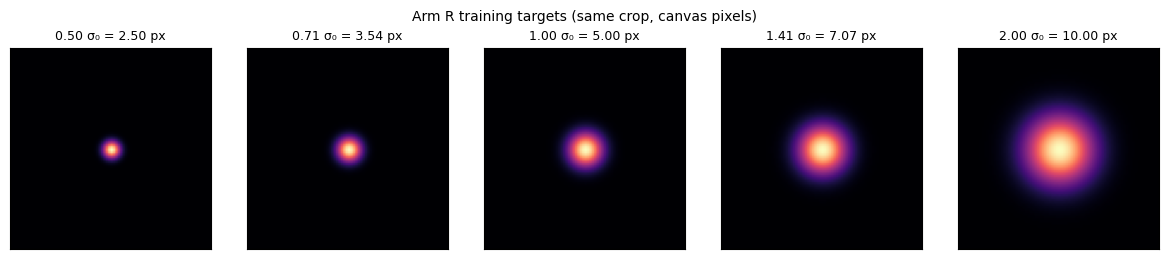

In [5]:
def arm_covariances(arm, width_mult, sigma0_px, k=K):
    """Per-landmark target covariance in the un-augmented canvas frame, px^2, shape (k, 2, 2)."""
    if arm == "R":
        s = width_mult * sigma0_px
        return np.tile(np.eye(2) * s * s, (k, 1, 1))
    raise NotImplementedError("This notebook defines arm R only; the other arms add their own branch here.")

_YY = {}
def make_targets(pts, cov, H=None, W=None):
    """pts (B,K,2) canvas px [x,y]; cov (B,K,2,2). Returns (B,K,H,W) float32 Gaussians with peak 1."""
    H, W = H or H_C, W or W_C
    key = (H, W, str(pts.device))
    if key not in _YY:
        _YY[key] = (torch.arange(W, device=pts.device, dtype=torch.float32).view(1, 1, 1, W),
                    torch.arange(H, device=pts.device, dtype=torch.float32).view(1, 1, H, 1))
    xs, ys = _YY[key]
    inv = torch.linalg.inv(cov.float())
    dx = xs - pts[..., 0, None, None]
    dy = ys - pts[..., 1, None, None]
    q = inv[..., 0, 0, None, None] * dx * dx + 2 * inv[..., 0, 1, None, None] * dx * dy + inv[..., 1, 1, None, None] * dy * dy
    return torch.exp(-0.5 * q)

def in_canvas(pts, H=None, W=None):
    """(B,K) bool: landmark lies inside the canvas (after augmentation)."""
    H, W = H or H_C, W or W_C
    return (pts[..., 0] >= 0) & (pts[..., 0] <= W - 1) & (pts[..., 1] >= 0) & (pts[..., 1] <= H - 1)

def mass_normalised_mse(pred, target, cov, valid=None):
    """Per-channel SSE divided by the analytic target mass 2*pi*sqrt(det S), averaged over valid channels.
    The analytic mass does not shrink when a target is cut by the canvas border, and landmarks pushed off the
    canvas by augmentation (valid=False) are left out of that step's loss instead of dividing by a near-zero mass."""
    mass = 2 * math.pi * torch.sqrt(torch.linalg.det(cov.float()))
    se = ((pred.float() - target) ** 2).sum(dim=(2, 3))
    per = se / mass
    if valid is None:
        return per.mean()
    valid = valid.to(per.dtype)
    return (per * valid).sum() / valid.sum().clamp_min(1)

# check: target mass equals 2*pi*sigma^2 for an interior landmark at every width
_chk = []
for wl, w in WIDTHS.items():
    c = torch.tensor(arm_covariances("R", w, SIGMA0_PX)[None])
    p = torch.tensor([[[W_C / 2 + 0.3, H_C / 2 - 0.2]] * K], dtype=torch.float32)
    t = make_targets(p, c)
    _chk.append(float(t[0, 0].sum()) / (2 * math.pi * (w * SIGMA0_PX) ** 2))
assert all(abs(r - 1) < 0.02 for r in _chk), _chk

fig_t, axs = plt.subplots(1, 5, figsize=(12, 2.6))
p = torch.tensor([[[W_C / 2, H_C / 2]] * K], dtype=torch.float32)
half = min(int(4 * 2.0 * SIGMA0_PX) + 2, H_C // 2, W_C // 2)
for ax, (wl, w) in zip(axs, WIDTHS.items()):
    t = make_targets(p, torch.tensor(arm_covariances("R", w, SIGMA0_PX)[None]))[0, 0].numpy()
    ax.imshow(t[H_C // 2 - half:H_C // 2 + half, W_C // 2 - half:W_C // 2 + half], cmap="magma", vmin=0, vmax=1)
    ax.set_title(f"{wl} σ₀ = {w * SIGMA0_PX:.2f} px", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig_t.suptitle("Arm R training targets (same crop, canvas pixels)", fontsize=10)
fig_t.tight_layout()
fig_t.savefig(Path(RUN_ROOT) / "HTO_round_targets.png", dpi=150)

## 4. Augmented training set

Per-sample randomness comes from `default_rng([seed, epoch, index])`, so two arms with the same seed see exactly the same images,
augmentations and batch order; only the target differs. There is no horizontal flip: all cephalograms face the same way, and a
flip would also mirror the error geometry.

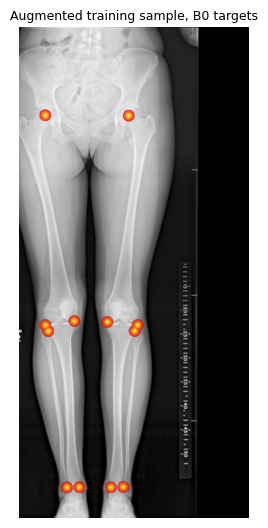

In [6]:
AUG = PROTOCOL["augmentation"]

class TrainSet(torch.utils.data.Dataset):
    def __init__(self, ids, seed, augment=True):
        self.ids, self.seed, self.augment, self.epoch = list(ids), int(seed), augment, 0

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, j):
        d = DATA[self.ids[j]]
        img, pts = d["img"], d["gt_canvas"]
        rot = np.eye(2)
        x = img.astype(np.float32) / 255.0
        if self.augment:
            rng = np.random.default_rng([self.seed, self.epoch, j])
            th = math.radians(rng.uniform(-AUG["rot_deg"], AUG["rot_deg"]))
            sc = math.exp(rng.uniform(math.log(AUG["scale"][0]), math.log(AUG["scale"][1])))
            sh = rng.uniform(-AUG["shift_frac"], AUG["shift_frac"], 2) * np.array([W_C, H_C])
            rot = np.array([[math.cos(th), -math.sin(th)], [math.sin(th), math.cos(th)]])
            A = sc * rot
            c = np.array([(W_C - 1) / 2, (H_C - 1) / 2])
            b = c + sh - A @ c
            M = np.hstack([A, b[:, None]])
            x = cv2.warpAffine(x, M, (W_C, H_C), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
            pts = pts @ A.T + b
            g = math.exp(rng.uniform(math.log(AUG["gamma"][0]), math.log(AUG["gamma"][1])))
            x = np.clip(x, 0, 1) ** g
            x = x * (1 + rng.uniform(-AUG["contrast"], AUG["contrast"])) + rng.uniform(-AUG["brightness"], AUG["brightness"])
        x = (x - x.mean()) / (x.std() + 1e-6)
        return (torch.from_numpy(x[None].astype(np.float32)), torch.from_numpy(pts.astype(np.float32)),
                torch.from_numpy(rot.astype(np.float32)))

def epoch_order(seed, epoch, n):
    return np.random.default_rng([seed, epoch, 10 ** 6]).permutation(n).tolist()

def plain_batch(ids):
    xs = []
    for i in ids:
        x = DATA[i]["img"].astype(np.float32) / 255.0
        xs.append((x - x.mean()) / (x.std() + 1e-6))
    return torch.from_numpy(np.stack(xs)[:, None])

# visual check: one augmented sample with its B0 targets
_ds = TrainSet(TRAIN_IDS, seed=1)
_x, _p, _r = _ds[0]
_cov = torch.tensor(arm_covariances("R", 1.0, SIGMA0_PX)[None]).float()
_t = make_targets(_p[None], _r[None, None] @ _cov @ _r[None, None].transpose(-1, -2))[0].amax(0)
fig_a, ax = plt.subplots(figsize=(2.6, 5.4))
ax.imshow(_x[0], cmap="gray")
ax.imshow(np.ma.masked_less(_t.numpy(), 0.05), cmap="autumn", alpha=0.8)
ax.set_title("Augmented training sample, B0 targets", fontsize=9)
ax.axis("off")
fig_a.tight_layout()
fig_a.savefig(Path(RUN_ROOT) / "HTO_B0_augmented_sample.png", dpi=150)

## 5. Network: UNet-64, 4 levels (High tier)

The proposal's tier table gives 31.0 M parameters and 491 GMACs at 768² for 12 heatmaps without batch norm. With 19 heatmaps,
batch norm and the 768 × 640 ISBI canvas, the counts are 31.04 M and ≈ 410 GMACs. The parameter count is asserted.

In [7]:
class DoubleConv(nn.Sequential):
    def __init__(self, ci, co):
        super().__init__(nn.Conv2d(ci, co, 3, padding=1, bias=True), nn.BatchNorm2d(co), nn.ReLU(inplace=True),
                         nn.Conv2d(co, co, 3, padding=1, bias=True), nn.BatchNorm2d(co), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=K, base=64, levels=4):
        super().__init__()
        ch = [base * 2 ** i for i in range(levels + 1)]
        self.down = nn.ModuleList()
        c = in_ch
        for i in range(levels):
            self.down.append(DoubleConv(c, ch[i])); c = ch[i]
        self.bottom = DoubleConv(ch[levels - 1], ch[levels])
        self.up = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in reversed(range(levels))])
        self.dec = nn.ModuleList([DoubleConv(2 * ch[i], ch[i]) for i in reversed(range(levels))])
        self.head = nn.Conv2d(ch[0], out_ch, 1)

    def forward(self, x):
        skips = []
        for blk in self.down:
            x = blk(x); skips.append(x); x = F.max_pool2d(x, 2)
        x = self.bottom(x)
        for up, dec, s in zip(self.up, self.dec, reversed(skips)):
            x = dec(torch.cat([up(x), s], 1))
        return self.head(x)

N_PARAMS = sum(p.numel() for p in UNet(base=UNET_BASE).parameters())
if not SMOKE_TEST:
    assert abs(N_PARAMS - 31.04e6) < 0.02e6, N_PARAMS
assert H_C % 16 == 0 and W_C % 16 == 0
print("UNet base", UNET_BASE, "| parameters", f"{N_PARAMS / 1e6:.3f} M")

UNet base 64 | parameters 31.043 M


## 6. Decoders

All four decoders run on the same checkpoints at no training cost (plan §4.2, convention 3). The window radius is the same in every
arm, so the decoder does not change with the target. `gaussfit` also returns the covariance of the fitted heatmap peak, which records
whether the predicted heatmap itself follows the target shape.

* `argmax`: integer peak (gives the rounding cost).
* `quadratic`: second-order Taylor step on the log heatmap in the 3 × 3 neighbourhood of the peak (PROVISIONAL primary).
* `softargmax_local`: centroid of the positive heatmap inside the window.
* `gaussfit`: weighted least squares of a full-covariance 2-D Gaussian to the log heatmap where it exceeds 10% of the peak.

In [8]:
def heatmap_windows(hm, r=None):
    """hm (B,K,H,W) float tensor -> integer peaks (B,K,2) [x,y] and windows (B,K,2r+1,2r+1) as numpy (NaN outside image)."""
    r = r or R_WIN
    B, Kk, H, W = hm.shape
    flat = hm.reshape(B, Kk, -1).argmax(-1)
    iy, ix = (flat // W), (flat % W)
    pad = F.pad(hm, (r, r, r, r), value=float("nan"))
    ar = torch.arange(2 * r + 1, device=hm.device)
    idx_y = (iy[..., None] + ar)[..., None].expand(B, Kk, 2 * r + 1, W + 2 * r)
    rows = torch.gather(pad, 2, idx_y)
    idx_x = (ix[..., None] + ar)[:, :, None, :].expand(B, Kk, 2 * r + 1, 2 * r + 1)
    win = torch.gather(rows, 3, idx_x)
    peaks = torch.stack([ix, iy], -1)
    return peaks.cpu().numpy().astype(np.float64), win.float().cpu().numpy().astype(np.float64)

_GRID = {}
def decode_window(w):
    """w: (2r+1,2r+1) window centred on the integer peak. Returns offsets (dx,dy) per decoder and the fitted covariance."""
    r = w.shape[0] // 2
    out = {"argmax": (0.0, 0.0)}
    peak = w[r, r]
    # quadratic (Taylor step on the log heatmap)
    off = (0.0, 0.0)
    nb = w[r - 1:r + 2, r - 1:r + 2]
    if peak > 0 and np.all(np.isfinite(nb)):
        L = np.log(np.clip(nb, 1e-6 * peak, None))
        gx, gy = (L[1, 2] - L[1, 0]) / 2, (L[2, 1] - L[0, 1]) / 2
        hxx, hyy = L[1, 2] - 2 * L[1, 1] + L[1, 0], L[2, 1] - 2 * L[1, 1] + L[0, 1]
        hxy = (L[2, 2] - L[2, 0] - L[0, 2] + L[0, 0]) / 4
        Hm = np.array([[hxx, hxy], [hxy, hyy]])
        if hxx < 0 and np.linalg.det(Hm) > 0:
            o = -np.linalg.solve(Hm, [gx, gy])
            off = tuple(float(v) for v in np.clip(o, -1, 1))
    out["quadratic"] = off
    # local soft-argmax
    if r not in _GRID:
        g = np.arange(-r, r + 1, dtype=np.float64)
        _GRID[r] = np.meshgrid(g, g)
    gx_, gy_ = _GRID[r]
    pw = np.where(np.isfinite(w), np.clip(w, 0, None), 0.0)
    out["softargmax_local"] = ((pw * gx_).sum() / pw.sum(), (pw * gy_).sum() / pw.sum()) if pw.sum() > 0 else (0.0, 0.0)
    # Gaussian fit (falls back to the quadratic step)
    out["gaussfit"], out["gauss_cov"] = off, (np.nan, np.nan, np.nan)
    m = (np.isfinite(w) & (w > 0.1 * peak)) if peak > 0 else np.zeros(w.shape, bool)
    if m.sum() >= 6:
        X, Y, V = gx_[m], gy_[m], w[m]
        Amat = np.stack([np.ones_like(X), X, Y, X * X, X * Y, Y * Y], 1)
        sw = np.sqrt(V)
        coef, *_ = np.linalg.lstsq(Amat * sw[:, None], np.log(V) * sw, rcond=None)
        A2 = np.array([[coef[3], coef[4] / 2], [coef[4] / 2, coef[5]]])
        if np.all(np.linalg.eigvalsh(A2) < 0):
            S = -0.5 * np.linalg.inv(A2)
            mu = S @ coef[1:3]
            if np.all(np.abs(mu) <= r):
                out["gaussfit"], out["gauss_cov"] = (float(mu[0]), float(mu[1])), (S[0, 0], S[0, 1], S[1, 1])
    return out

# unit check on noiseless Gaussians at sub-pixel positions
_errs = {d: [] for d in PROTOCOL["decoders"]}
for (x0, y0) in [(40.3, 31.7), (52.6, 20.2), (33.5, 44.5)]:
    for sg in (SIGMA0_PX * 2 ** -0.5, SIGMA0_PX):
        cov = torch.tensor(np.eye(2)[None, None] * sg ** 2)
        hm = make_targets(torch.tensor([[[x0, y0]]], dtype=torch.float32), cov, 80, 96)
        pk, win = heatmap_windows(hm)
        dec = decode_window(win[0, 0])
        for d in PROTOCOL["decoders"]:
            _errs[d].append(math.hypot(pk[0, 0, 0] + dec[d][0] - x0, pk[0, 0, 1] + dec[d][1] - y0))
_maxerr = {d: round(max(v), 4) for d, v in _errs.items()}
assert _maxerr["quadratic"] < 0.02 and _maxerr["gaussfit"] < 0.02 and _maxerr["softargmax_local"] < 0.1, _maxerr
print("decoder max error on noiseless Gaussians (px):", _maxerr)

decoder max error on noiseless Gaussians (px): {'argmax': 0.7071, 'quadratic': 0.0, 'softargmax_local': 0.0144, 'gaussfit': 0.0}


## 7. Prediction and per-landmark statistics

In [9]:
@torch.no_grad()
def predict(model, ids, batch=4):
    model.eval()
    recs = []
    for k0 in range(0, len(ids), batch):
        bid = ids[k0:k0 + batch]
        x = plain_batch(bid).to(DEVICE)
        with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
            hm = model(x)
        peaks, wins = heatmap_windows(hm.float())
        for b, i in enumerate(bid):
            d = DATA[i]
            for k in range(K):
                dec = decode_window(wins[b, k])
                for name in PROTOCOL["decoders"]:
                    xc, yc = peaks[b, k, 0] + dec[name][0], peaks[b, k, 1] + dec[name][1]
                    xo, yo = canvas_to_orig(xc, d["s"]), canvas_to_orig(yc, d["s"])
                    dx, dy = (xo - d["gt_orig"][k, 0]) * MM, (yo - d["gt_orig"][k, 1]) * MM
                    recs.append((i, d["subset"], k + 1, name, xo, yo, dx, dy, math.hypot(dx, dy),
                                 wins[b, k, R_WIN, R_WIN], *dec["gauss_cov"]))
    return pd.DataFrame(recs, columns=["image_id", "subset", "landmark", "decoder", "x_pred", "y_pred",
                                       "dx_mm", "dy_mm", "r_mm", "peak", "fit_sxx", "fit_sxy", "fit_syy"])

def _madsd(v):
    return 1.4826 * float(np.median(np.abs(v - np.median(v))))

def spread_stats(dx, dy, fail_mm=None):
    """Spread after the gross-failure cut. Major-axis angle in degrees from +x towards +y (image frame)."""
    fail_mm = PROTOCOL["gross_failure_mm"] if fail_mm is None else fail_mm
    dx, dy = np.asarray(dx, float), np.asarray(dy, float)
    r = np.hypot(dx, dy)
    keep = r <= fail_mm
    out = {"n": len(r), "n_kept": int(keep.sum()), "fail_rate": float(1 - keep.mean()), "mre_mm": float(r.mean())}
    for t in PROTOCOL["sdr_mm"]:
        out[f"sdr_{t:g}mm"] = float((r <= t).mean())
    if keep.sum() >= 5:
        ex, ey = dx[keep], dy[keep]
        C = np.cov(np.stack([ex, ey]))
        ev, V = np.linalg.eigh(C)
        ang = (math.degrees(math.atan2(V[1, 1], V[0, 1])) + 90) % 180 - 90
        out.update({"bias_x_mm": ex.mean(), "bias_y_mm": ey.mean(), "sd_x": math.sqrt(C[0, 0]), "sd_y": math.sqrt(C[1, 1]),
                    "cov_xy": C[0, 1], "sd_iso": math.sqrt(np.trace(C) / 2), "sd_major": math.sqrt(max(ev[1], 0)),
                    "sd_minor": math.sqrt(max(ev[0], 0)), "angle_major_deg": ang,
                    "sd_ratio": math.sqrt(ev[1] / ev[0]) if ev[0] > 0 else np.nan,
                    "madsd_x": _madsd(ex), "madsd_y": _madsd(ey)})
    return out

def summarise(pred):
    rows = []
    for (dec, lm), g in pred.groupby(["decoder", "landmark"]):
        rows.append({"decoder": dec, "landmark": lm, **spread_stats(g.dx_mm, g.dy_mm)})
    for dec, g in pred.groupby("decoder"):   # landmark 0 = all landmarks pooled (accuracy only)
        st = spread_stats(g.dx_mm, g.dy_mm)
        rows.append({"decoder": dec, "landmark": 0, **{k: v for k, v in st.items()
                                                      if k in ("n", "n_kept", "fail_rate", "mre_mm") or k.startswith("sdr")}})
    return pd.DataFrame(rows)

## 8. Training one run

**Checkpoint names carry their hash.** Every saved model is written as `<stem>_<sha8>.pt`, where `sha8` is the last 8 hex
characters of the file's SHA-256 (for example `final_3fa9c01e.pt`, `snap_e50pct_…pt`, `snap_e75pct_…pt`). The file is written to a
temporary name, hashed, then renamed, so the suffix always matches the content. The full SHA-256 goes into `config.json`
(`checkpoints`), the `DONE` marker (protocol hash, final file name, full SHA-256), and the `checkpoint_sha8` column of
`predictions_test.csv.gz` and `summary_final.csv`. Each prediction row therefore names the exact model that produced it. The suffix is
re-checked whenever a checkpoint is loaded. `last.pt` is only the overwritten resume file and is deleted when the run finishes.

In [10]:
CONV_IDS = sorted(np.random.default_rng(0).choice(TRAIN_IDS, 20, replace=False).tolist())

def lr_at(it, iters_per_epoch, total_iters):
    o = PROTOCOL["optimiser"]
    warm = o["warmup_epochs"] * iters_per_epoch
    if it < warm:
        return o["lr"] * (it + 1) / warm
    prog = (it - warm) / max(1, total_iters - warm)
    return 1e-6 + 0.5 * (o["lr"] - 1e-6) * (1 + math.cos(math.pi * prog))

def file_sha256(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def save_checkpoint(state, out_dir, stem):
    """Save to <stem>_<sha8>.pt, where sha8 = last 8 hex characters of the file's SHA-256.
    Any older <stem>_<8 hex>.pt in the same run folder (e.g. from an interrupted save) is removed first."""
    out_dir = Path(out_dir)
    for old in out_dir.glob(f"{stem}_*.pt"):
        if re.fullmatch(rf"{re.escape(stem)}_[0-9a-f]{{8}}\.pt", old.name):
            old.unlink()
    tmp = out_dir / f"{stem}.pt.tmp"
    torch.save(state, tmp)
    sha = file_sha256(tmp)
    path = out_dir / f"{stem}_{sha[-8:]}.pt"
    os.replace(tmp, path)
    return path, sha

def find_checkpoint(out_dir, stem, verify=True):
    """Return (path, sha256) of the single <stem>_<sha8>.pt in out_dir, or (None, None). Verifies the suffix."""
    hits = [p for p in Path(out_dir).glob(f"{stem}_*.pt")
            if re.fullmatch(rf"{re.escape(stem)}_[0-9a-f]{{8}}\.pt", p.name)]
    if not hits:
        return None, None
    assert len(hits) == 1, f"more than one {stem} checkpoint in {out_dir}: {[p.name for p in hits]}"
    sha = file_sha256(hits[0]) if verify else None
    if verify:
        assert sha[-8:] == hits[0].stem.rsplit("_", 1)[1], f"{hits[0].name}: content does not match its SHA-256 suffix"
    return hits[0], sha

def _grad_scaler():
    enabled = AMP_DTYPE == torch.float16
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)

try:
    from tqdm.auto import tqdm as _tqdm
except ImportError:
    _tqdm = None

class _PrintProgress:
    """Fallback when tqdm is missing: one line at every convergence check (every 25 epochs)."""
    def __init__(self, desc, total, initial):
        self.desc, self.total, self.n, self.t0, self.post = desc, total, initial, time.time(), {}
        self.n0 = initial
    def set_postfix(self, refresh=False, **kw):
        self.post = kw
    def update(self, k=1):
        self.n += k
        if self.n % 25 == 0 or self.n == self.total:
            eta = (time.time() - self.t0) / max(self.n - self.n0, 1) * (self.total - self.n) / 3600
            print(f"{self.desc}: epoch {self.n}/{self.total}, " + ", ".join(f"{k} {v}" for k, v in self.post.items())
                  + f", ETA {eta:.2f} h", flush=True)
    def close(self):
        pass

def epoch_bar(run_id, start_ep):
    desc = run_id.replace(f"C0_{DATASET}_{TIER}_{ARM}_", "")
    if not PROGRESS_BAR:
        return None
    if _tqdm is None:
        return _PrintProgress(desc, EPOCHS, start_ep)
    return _tqdm(total=EPOCHS, initial=start_ep, desc=desc, unit="ep", mininterval=1.0, dynamic_ncols=True, leave=True)

def train_run(run):
    out = Path(RUN_ROOT) / run["run_id"]
    if (out / "DONE").exists():
        print("skip (done):", run["run_id"]); return
    out.mkdir(parents=True, exist_ok=True)
    seed = int(run["seed"])
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    model = UNet(base=UNET_BASE).to(DEVICE)
    o = PROTOCOL["optimiser"]
    opt = torch.optim.AdamW(model.parameters(), lr=o["lr"], weight_decay=o["weight_decay"])
    scaler = _grad_scaler()
    ds = TrainSet(TRAIN_IDS, seed)
    ipe = len(TRAIN_IDS) // BATCH_SIZE
    total = EPOCHS * ipe
    base_cov = torch.tensor(arm_covariances(ARM, run["width_mult"], SIGMA0_PX), dtype=torch.float32, device=DEVICE)
    start_ep, log = 0, []
    if (out / "last.pt").exists():
        ck = torch.load(out / "last.pt", map_location=DEVICE, weights_only=False)
        assert ck["protocol_hash"] == PROTOCOL_HASH, "protocol changed since this run started"
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        start_ep, log = ck["epoch"] + 1, ck["log"]
        print("resume", run["run_id"], "from epoch", start_ep)
    cfg = {"run": run, "protocol": PROTOCOL, "protocol_hash": PROTOCOL_HASH, "env": ENV_INFO, "sigma0_px": SIGMA0_PX,
           "unet_base": UNET_BASE, "n_params": N_PARAMS, "conv_ids": CONV_IDS,
           "started": dt.datetime.now().isoformat(timespec="seconds")}
    (out / "config.json").write_text(json.dumps(cfg, indent=1, default=str))
    snaps = {max(int(EPOCHS * 0.5) - 1, 0): "e50pct", max(int(EPOCHS * 0.75) - 1, 0): "e75pct"}
    t_run = time.time()
    bar = epoch_bar(run["run_id"], start_ep)
    for ep in range(start_ep, EPOCHS):
        model.train(); ds.epoch = ep
        dl = torch.utils.data.DataLoader(ds, batch_size=BATCH_SIZE, sampler=epoch_order(seed, ep, len(ds)),
                                         num_workers=NUM_WORKERS, drop_last=True, pin_memory=DEVICE.type == "cuda")
        t0, losses, n_off = time.time(), [], 0
        for it_in, (x, p, rot) in enumerate(dl):
            it = ep * ipe + it_in
            for gp in opt.param_groups:
                gp["lr"] = lr_at(it, ipe, total)
            x, p, rot = x.to(DEVICE, non_blocking=True), p.to(DEVICE), rot.to(DEVICE)
            cov = rot[:, None] @ base_cov[None] @ rot[:, None].transpose(-1, -2)
            tgt = make_targets(p, cov)
            with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
                pred = model(x)
            valid = in_canvas(p)
            n_off += int((~valid).sum())
            loss = mass_normalised_mse(pred, tgt, cov, valid)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            losses.append(loss.item())
        rec = {"epoch": ep + 1, "loss": float(np.mean(losses)), "lr": float(opt.param_groups[0]["lr"]),
               "sec": time.time() - t0, "n_landmarks_off_canvas": n_off}
        if (ep + 1) % 25 == 0 or ep + 1 == EPOCHS:
            pr = predict(model, CONV_IDS)
            rec["conv_mre_mm"] = float(pr[pr.decoder == PROTOCOL["primary_decoder"]].r_mm.mean())
        log.append(rec)
        if bar is not None:
            mre = next((r["conv_mre_mm"] for r in reversed(log) if "conv_mre_mm" in r), None)
            bar.set_postfix(loss=f"{rec['loss']:.4g}", train_mre_px="-" if mre is None else f"{mre:.1f}",
                            s_per_ep=f"{rec['sec']:.1f}", refresh=False)
            bar.update(1)
        if ep in snaps:
            save_checkpoint({k: v.half() if v.is_floating_point() else v for k, v in model.state_dict().items()},
                            out, f"snap_{snaps[ep]}")
        if (ep + 1) % 50 == 0 or ep + 1 == EPOCHS:
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(), "epoch": ep,
                        "log": log, "protocol_hash": PROTOCOL_HASH}, out / "last.pt")
            pd.DataFrame(log).to_csv(out / "train_log.csv", index=False)
        if bar is None and ep == start_ep:
            print(f"{run['run_id']}: epoch {ep + 1} took {rec['sec']:.1f} s -> projected "
                  f"{rec['sec'] * (EPOCHS - ep) / 3600:.2f} h for the rest of the run")
    if bar is not None:
        bar.close()
    final_path, final_sha = save_checkpoint(model.state_dict(), out, "final")
    lg = pd.DataFrame(log); lg.to_csv(out / "train_log.csv", index=False)
    cm = lg.conv_mre_mm.dropna().values
    converged = bool(len(cm) >= 8 and abs(cm[-4:].mean() - cm[-8:-4].mean()) <= 0.02 * cm[-8:-4].mean())
    # evaluation: final checkpoint (the one used) and snapshots (convergence report only, never selected)
    preds, ckpts = [], {}
    stems = {"final": "final", **{t: f"snap_{t}" for t in sorted(set(snaps.values()))}}
    for tag, stem in stems.items():
        path, sha = find_checkpoint(out, stem)
        assert path is not None, f"{run['run_id']}: expected checkpoint {stem}_<sha8>.pt not found"
        ckpts[tag] = {"file": path.name, "sha256": sha}
        model.load_state_dict({k: v.float() if v.is_floating_point() else v
                               for k, v in torch.load(path, map_location=DEVICE).items()})
        pr = predict(model, TEST_IDS)
        pr.insert(0, "checkpoint_sha8", sha[-8:]); pr.insert(0, "checkpoint", tag); preds.append(pr)
    assert ckpts["final"]["sha256"] == final_sha
    pred = pd.concat(preds, ignore_index=True)
    assert set(pred.checkpoint) == set(stems), f"evaluated {set(pred.checkpoint)}, expected {set(stems)}"
    pred.insert(0, "run_id", run["run_id"])
    pred.to_csv(out / "predictions_test.csv.gz", index=False)
    summ = summarise(pred[pred.checkpoint == "final"])
    summ.insert(0, "checkpoint_sha8", final_sha[-8:]); summ.insert(0, "run_id", run["run_id"])
    summ.to_csv(out / "summary_final.csv", index=False)
    cfg.update({"finished": dt.datetime.now().isoformat(timespec="seconds"),
                "train_hours_this_session": (time.time() - t_run) / 3600,
                "sec_per_epoch_median": float(lg.sec.median()), "converged": converged, "checkpoints": ckpts})
    (out / "config.json").write_text(json.dumps(cfg, indent=1, default=str))
    (out / "last.pt").unlink(missing_ok=True)
    (out / "DONE").write_text(f"{PROTOCOL_HASH}\n{final_path.name}\n{final_sha}\n")
    s0 = summ[(summ.decoder == PROTOCOL["primary_decoder"]) & (summ.landmark == 0)].iloc[0]
    print(f"done {run['run_id']} -> {final_path.name}: MRE {s0.mre_mm:.1f} px, SDR 50 px {s0.sdr_50mm:.3f}, "
          f"gross failures {s0.fail_rate:.3f}, converged {converged}, {lg.sec.median() * EPOCHS / 3600:.2f} h/run")

## 9. Execute the selected runs (one fold per run: training = the other four folds, test = the held-out fold)

In [11]:
todo = RUN_TABLE if RUN_IDS == "all" else RUN_TABLE[RUN_TABLE.run_id.isin(RUN_IDS)]
assert len(todo) > 0, "RUN_IDS matched no run"
for _, run in todo.iterrows():
    f = int(run.fold)
    TEST_IDS = FOLD_IDS[f]
    TRAIN_IDS = sorted(i for i in DATA if i not in TEST_IDS)
    CONV_IDS = sorted(np.random.default_rng(0).choice(TRAIN_IDS, min(20, len(TRAIN_IDS)), replace=False).tolist())
    for i, d in DATA.items():
        d["subset"] = "test" if i in TEST_IDS else "train"
    print(f"{run.run_id}: fold {f} | train {len(TRAIN_IDS)} | test {len(TEST_IDS)} | {len(TRAIN_IDS) // BATCH_SIZE} iterations/epoch")
    train_run(run.to_dict())

C0_HTO_High_R_w1.00_f2_s101: fold 2 | train 43 | test 11 | 10 iterations/epoch


w1.00_f2_s101:   0%|          | 0/2960 [00:00<?, ?ep/s]

done C0_HTO_High_R_w1.00_f2_s101 -> final_a1c15dcb.pt: MRE 8.0 px, SDR 50 px 0.992, gross failures 0.000, converged True, 1.80 h/run


## 10. Status (the forecast analysis runs locally in `C0_HTO_prescreen.ipynb` §5)

Per finished run: MRE, gross-failure rate and fine-scatter SD per landmark (primary decoder, original px). A landmark with more than
5 % gross failures in a fold is flagged; such cells are left out of m in the pre-screen.

In [12]:
stat = []
for _, run in RUN_TABLE.iterrows():
    p = Path(RUN_ROOT) / run.run_id / "summary_final.csv"
    if not p.exists():
        continue
    s_ = pd.read_csv(p)
    s_ = s_[(s_.decoder == PROTOCOL["primary_decoder"]) & (s_.landmark > 0)]
    for _, r in s_.iterrows():
        stat.append({"fold": run.fold, "landmark": LANDMARKS[int(r.landmark) - 1], "mre_px": r.mre_mm, "fail_rate": r.fail_rate,
                     "sd_major_px": r.get("sd_major"), "sd_minor_px": r.get("sd_minor")})
print(f"B0 runs done: {sum((Path(RUN_ROOT) / r / 'DONE').exists() for r in RUN_TABLE.run_id)} of {len(RUN_TABLE)}")
if stat:
    STAT = pd.DataFrame(stat)
    STAT.round(3).to_csv(Path(RUN_ROOT) / "HTO_B0_status.csv", index=False)
    display(STAT.pivot_table(index="landmark", columns="fold", values=["mre_px", "fail_rate"]).round(3))

B0 runs done: 2 of 5


fail_rate         mre_px         
fold                      2      4       2        4
landmark                                           
left ankle_inner        0.0  0.000   4.721    5.695
left ankle_outer        0.0  0.000   4.220    5.616
left femur_head         0.0  0.091  10.613  355.544
left knee_inner         0.0  0.000   6.555    8.651
left knee_outer         0.0  0.000   7.987    9.919
left ost_point          0.0  0.000  16.568   10.178
right ankle_inner       0.0  0.000   3.470    4.951
right ankle_outer       0.0  0.000   7.844    9.174
right femur_head        0.0  0.000   8.083   16.926
right knee_inner        0.0  0.000   6.372    4.987
right knee_outer        0.0  0.000   6.847   10.282
right ost_point         0.0  0.000  12.786   14.191